# Gráficos comparativos: Performance Profiles e boxplots

- **Instâncias**: 50 blocos (A=20, B=15, X=15); 30 seeds por instância e algoritmo.
- **RPD (%)** = `(best − obj) / best · 100` (maximização), com `best` de `best_solutions/best_objectives.csv`.
- **Seções**: (1) Performance Profiles de Dolan & Moré (RPD e tempo); (2) boxplots.
- Os testes estatísticos ficam **exclusivamente** em `testes_estatisticos.ipynb`.
- A seção de curvas de convergência não está incluída (os resultados atuais não têm traço de execução).

In [1]:
from pathlib import Path
import math
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "utils" / "__init__.py").exists())
RESULTS = ROOT / "project" / "results"
BEST_CSV = ROOT / "best_solutions" / "best_objectives.csv"
IMG = ROOT / "notebooks" / "resultados" / "img"; IMG.mkdir(parents=True, exist_ok=True)

DATASETS = ["a", "b", "x"]
ALGOS = {"order_based": "OrderBased", "aisle_based": "AisleBased",
         "ils_vnd_all": "ILS-VND", "andre_feijo_all": "Santos e Baldotto (2025)"}
NOMES = list(ALGOS.values())
COR = dict(zip(NOMES, ["#7f7f7f", "#1f77b4", "#d62728", "#2ca02c"]))
TOL = 1e-4   # tolerância relativa de empate (mesma do testes_estatisticos.ipynb)
ALPHA = 0.05
RNG_SEED = 12345

def salvar(fig, nome):
    for ext in ("png", "pdf"):
        fig.savefig(IMG / f"{nome}.{ext}", dpi=200, bbox_inches="tight")

frames = []
for folder, label in ALGOS.items():
    for ds in DATASETS:
        for f in sorted((RESULTS / folder / ds).glob("instance_*.csv")):
            d = pd.read_csv(f, usecols=["objective", "exec_time"])
            d["algo"], d["dataset"], d["instance"] = label, ds, f.stem + ".txt"
            frames.append(d)
raw = pd.concat(frames, ignore_index=True)
best = pd.read_csv(BEST_CSV)
raw = raw.merge(best, left_on=["dataset", "instance"], right_on=["dataset", "instance"], how="left")
assert raw.best_objective.notna().all()
raw["rpd"] = (raw.best_objective - raw.objective) / raw.best_objective * 100

g = raw.groupby(["dataset", "instance", "algo"])
agg = g.agg(obj=("objective", "mean"), rpd=("rpd", "mean"), rpd_dp=("rpd", "std"),
            tempo=("exec_time", "mean"), n=("objective", "size")).reset_index()
print("Grupos com != 30 seeds:", int((agg.n != 30).sum()))
def pv(col): return agg.pivot(index=["dataset", "instance"], columns="algo", values=col)[NOMES]
OBJ, RPD, RPD_DP, TEMPO = pv("obj"), pv("rpd"), pv("rpd_dp"), pv("tempo")
assert not OBJ.isna().any().any()
N, K = OBJ.shape
ds_idx = OBJ.index.get_level_values("dataset")
print(f"Blocos N={N} | algoritmos k={K}")

Grupos com != 30 seeds: 0
Blocos N=50 | algoritmos k=4


## 1. Performance Profiles (Dolan & Moré)

Para cada instância `p` e algoritmo `s`, `r_{p,s} = c_{p,s} / min_s c_{p,s}` e `ρ_s(τ)` = fração de instâncias com `r ≤ τ`. `ρ_s(1)` é a fração de instâncias em que `s` é (um dos) melhores; o patamar para `τ` grande mede a robustez. Custo de qualidade: `c = 1 + RPD/100` (evita divisão por zero quando RPD = 0). Custo de tempo: `c` = tempo médio de execução (piso de 1 ms).

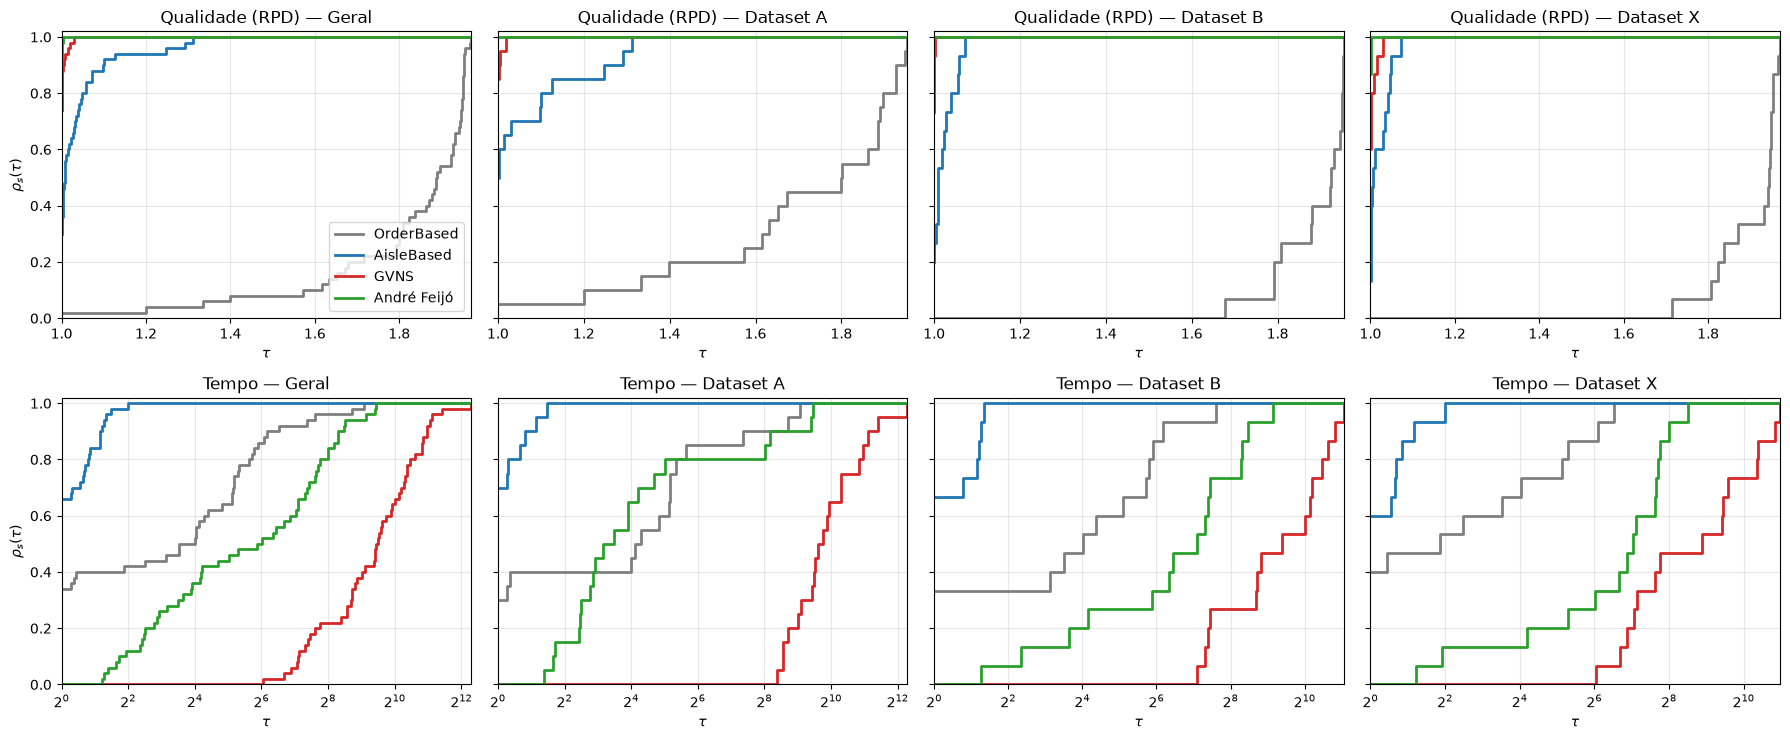

,ρ(1) qualidade,ρ(1) tempo,"ρ(τ=1,05) qualidade"
algo,,,
OrderBased,0.02,0.34,0.02
AisleBased,0.30,0.66,0.80
GVNS,0.74,0.00,1.00
Santos e Baldotto (2025),0.90,0.00,1.00


In [2]:
def razoes(C):
    return C.div(C.min(axis=1), axis=0)

def perfil(ax, C, titulo, xmax=None, log=True):
    r = razoes(C)
    tmax = r.values.max() if xmax is None else xmax
    taus = np.unique(np.concatenate([[1.0], r.values.ravel(), [tmax]]))
    taus = taus[taus <= tmax]
    for a in NOMES:
        rho = [(r[a] <= t + 1e-12).mean() for t in taus]
        ax.step(taus, rho, where="post", label=a, color=COR[a], lw=2)
    if log: ax.set_xscale("log", base=2)
    ax.set_ylim(0, 1.02); ax.set_xlim(1, tmax)
    ax.set_title(titulo); ax.grid(alpha=0.3)
    ax.set_xlabel(r"$\tau$")

CUSTO_Q = 1 + RPD / 100
CUSTO_T = TEMPO.clip(lower=1e-3)
grupos = [("Geral", slice(None))] + [(f"Dataset {d.upper()}", ds_idx == d) for d in DATASETS]

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharey=True)
for j, (nome, mask) in enumerate(grupos):
    sel = np.ones(N, bool) if isinstance(mask, slice) else np.asarray(mask)
    perfil(axes[0, j], CUSTO_Q[sel], f"Qualidade (RPD) — {nome}", log=False)
    perfil(axes[1, j], CUSTO_T[sel], f"Tempo — {nome}")
axes[0, 0].set_ylabel(r"$\rho_s(\tau)$"); axes[1, 0].set_ylabel(r"$\rho_s(\tau)$")
axes[0, 0].legend(loc="lower right")
fig.tight_layout(); salvar(fig, "perf_profile"); plt.show()

# Resumo numérico: rho(1) (vitórias) e rho no maior tau (robustez), qualidade e tempo
res = pd.DataFrame({
    "ρ(1) qualidade": (razoes(CUSTO_Q) <= 1 + 1e-12).mean(),
    "ρ(1) tempo": (razoes(CUSTO_T) <= 1 + 1e-12).mean(),
    "ρ(τ=1,05) qualidade": (razoes(CUSTO_Q) <= 1.05).mean(),
})
display(res.style.format("{:.2f}").set_caption("Resumo dos perfis de desempenho (todas as instâncias)"))

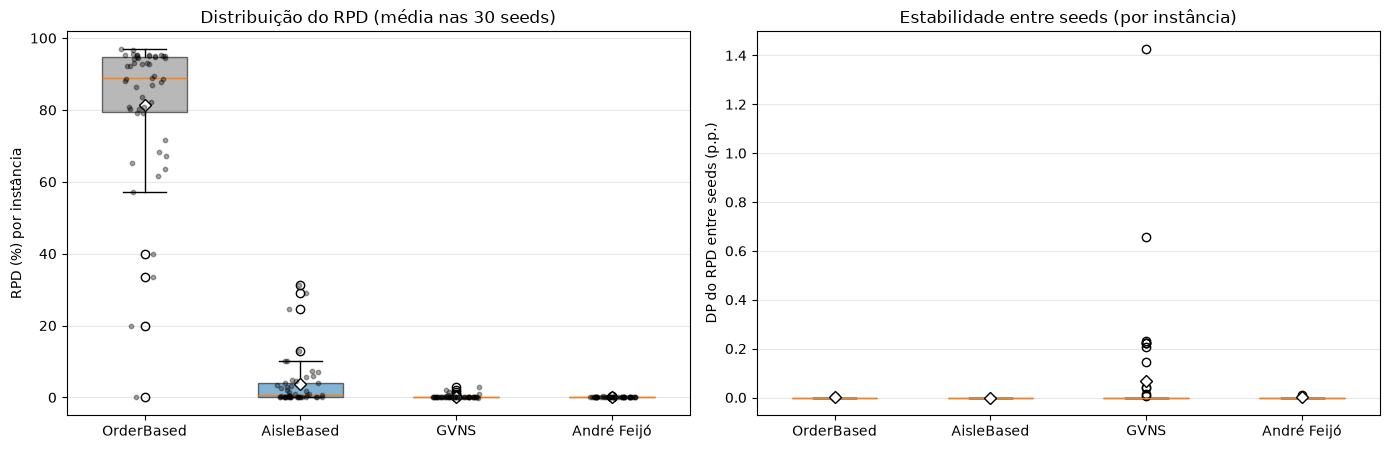

In [6]:
# --- Boxplots de RPD
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
dados = [RPD[a].values for a in NOMES]
bp = axes[0].boxplot(dados, tick_labels=NOMES, patch_artist=True, showmeans=True, widths=0.55,
                     meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k"))
for patch, a in zip(bp["boxes"], NOMES): patch.set_facecolor(COR[a]); patch.set_alpha(0.55)
rng_j = np.random.default_rng(RNG_SEED)
for i, a in enumerate(NOMES):
    axes[0].scatter(i + 1 + rng_j.uniform(-0.15, 0.15, N), RPD[a].values, s=10, color="k", alpha=0.35, zorder=3)
axes[0].set_ylabel("RPD (%) por instância"); axes[0].set_title("Distribuição do RPD (média nas 30 seeds)"); axes[0].grid(alpha=0.3, axis="y")

bp2 = axes[1].boxplot([RPD_DP[a].values for a in NOMES], tick_labels=NOMES, patch_artist=True, showmeans=True, widths=0.55,
                      meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k"))
for patch, a in zip(bp2["boxes"], NOMES): patch.set_facecolor(COR[a]); patch.set_alpha(0.55)
axes[1].set_ylabel("DP do RPD entre seeds (p.p.)"); axes[1].set_title("Estabilidade entre seeds (por instância)"); axes[1].grid(alpha=0.3, axis="y")
fig.tight_layout(); salvar(fig, "boxplot_rpd"); plt.show()